In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["figure.figsize"] = (8, 5)


In [16]:
df = sns.load_dataset("mpg")
df.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [17]:
print("Rows, Columns:", df.shape)
df.info()


# In[4]:


df[["mpg", "horsepower"]].describe()


# ## Step 4: Clean the data
# Models cannot handle empty values. Let's count them.

# In[5]:


df.isnull().sum()

Rows, Columns: (398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Rows after cleaning: 392


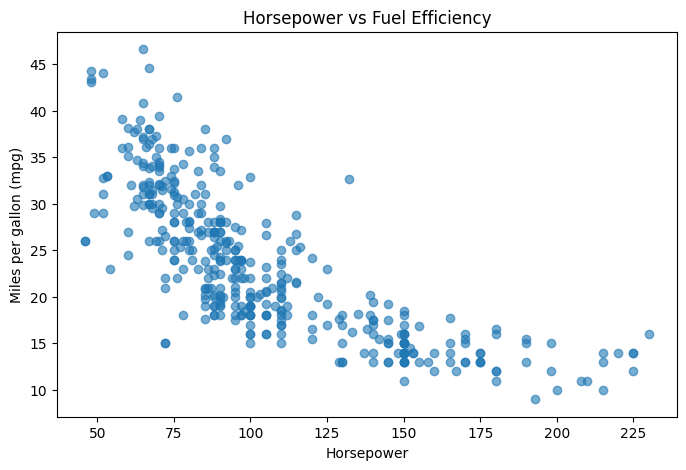

In [18]:
# horsepower has 6 missing values -> drop those rows
df = df.dropna(subset=["horsepower"])
print("Rows after cleaning:", len(df))


# ## Step 5: Visualize the relationship
# Always **look** at the data before building a model.

# In[7]:


plt.scatter(df["horsepower"], df["mpg"], alpha=0.6)
plt.xlabel("Horsepower")
plt.ylabel("Miles per gallon (mpg)")
plt.title("Horsepower vs Fuel Efficiency")
plt.show()


# **Ask the class:** What do you notice?
# - More horsepower → fewer miles per gallon (negative relationship).
# - The points form a **curve**, not a perfectly straight line. Remember this — it matters later!

# ## Step 6: Choose X (input) and y (output)
# - `X` must be **2-D** (a table), so we use double brackets `[["horsepower"]]`.
# - `y` is **1-D** (a single column).

In [19]:
# In[8]:


X = df[["horsepower"]]   # feature
y = df["mpg"]            # target
print(X.shape, y.shape)


# ## Step 7: Split into training and testing sets
# - **Training set (80%)** → the model learns from this.
# - **Test set (20%)** → kept hidden, used to check the model on *new* data.
# 
# Like studying from practice questions, then sitting a real exam with new questions.

# In[9]:



(392, 1) (392,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42   # random_state = same split every time
)
print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 313
Testing rows : 79


Intercept (b0): 40.606
Slope     (b1): -0.1626

Equation: mpg = 40.61 + (-0.1626) x horsepower
MAE : 3.78 mpg
RMSE: 4.71 mpg
R²  : 0.566


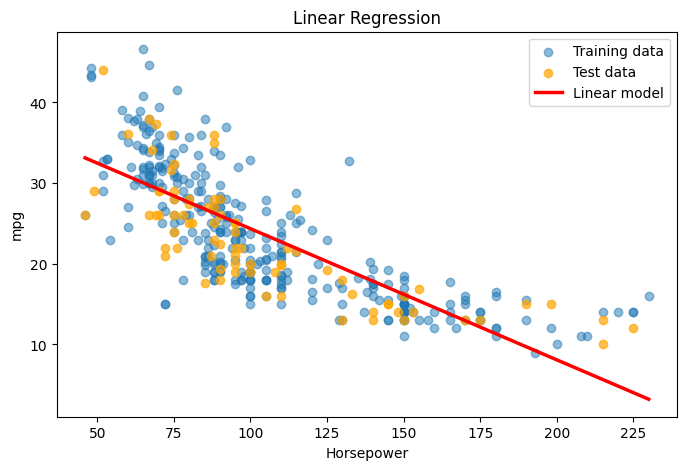

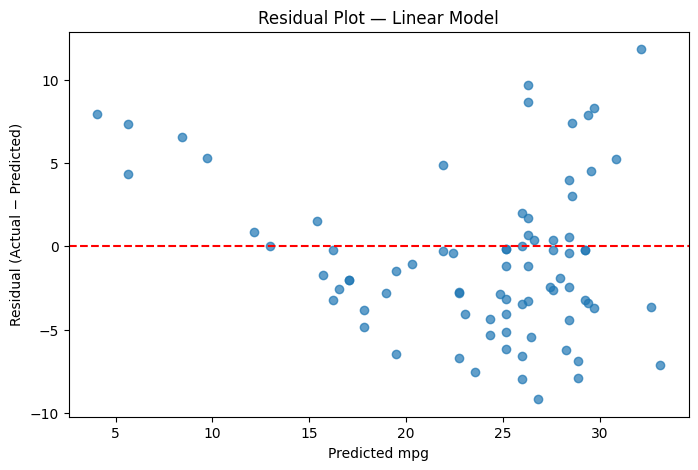

In [23]:
# ---
# # Part A: Linear Regression
# 
# The model draws the best straight line:
# 
# $$\text{mpg} = b_0 + b_1 \times \text{horsepower}$$
# 
# - $b_0$ = **intercept** (where the line meets the y-axis)
# - $b_1$ = **slope** (how much mpg changes when horsepower goes up by 1)
# 
# "Best" means the line with the smallest total squared error (**Least Squares**).
# 
# ## Step 8: Create and train the model

# In[10]:


lin_model = LinearRegression()
lin_model.fit(X_train, y_train)   # the model learns b0 and b1 here


# ## Step 9: Look at what the model learned

# In[11]:


b0 = lin_model.intercept_
b1 = lin_model.coef_[0]
print(f"Intercept (b0): {b0:.3f}")
print(f"Slope     (b1): {b1:.4f}")
print(f"\nEquation: mpg = {b0:.2f} + ({b1:.4f}) x horsepower")


# **Interpretation:** the slope is about **−0.16** → every extra 10 horsepower costs about **1.6 mpg**.

# ## Step 10: Make predictions on the test set

# In[12]:


y_pred_lin = lin_model.predict(X_test)

# compare a few actual vs predicted values
comparison = pd.DataFrame({
    "Horsepower": X_test["horsepower"].values[:8],
    "Actual mpg": y_test.values[:8],
    "Predicted mpg": y_pred_lin[:8].round(1),
})
comparison


# ## Step 11: Evaluate the model
# 
# | Metric | Meaning | Better when |
# |---|---|---|
# | **MAE** | Average size of the error (in mpg) | Lower |
# | **RMSE** | Like MAE but punishes big errors more | Lower |
# | **R²** | Share of the variation in mpg the model explains (0 to 1) | Higher |

# In[13]:


mae_lin  = mean_absolute_error(y_test, y_pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_test, y_pred_lin))
r2_lin   = r2_score(y_test, y_pred_lin)

print(f"MAE : {mae_lin:.2f} mpg")
print(f"RMSE: {rmse_lin:.2f} mpg")
print(f"R²  : {r2_lin:.3f}")


# ## Step 12: Draw the regression line

# In[14]:


x_line = pd.DataFrame({"horsepower": np.linspace(X["horsepower"].min(), X["horsepower"].max(), 200)})

plt.scatter(X_train, y_train, alpha=0.5, label="Training data")
plt.scatter(X_test, y_test, alpha=0.7, color="orange", label="Test data")
plt.plot(x_line, lin_model.predict(x_line), color="red", linewidth=2.5, label="Linear model")
plt.xlabel("Horsepower")
plt.ylabel("mpg")
plt.title("Linear Regression")
plt.legend()
plt.show()


# ## Step 13: Check the residuals (errors)
# **Residual = Actual − Predicted.**
# For a good model, residuals look like random noise around 0. A **pattern** means the model is missing something.

# In[15]:


residuals = y_test - y_pred_lin

plt.scatter(y_pred_lin, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted mpg")
plt.ylabel("Residual (Actual − Predicted)")
plt.title("Residual Plot — Linear Model")
plt.show()



In [28]:
# **Notice the U-shape!** The line is too high in the middle and too low at both ends.
# This tells us the true relationship is **curved** → let's try Polynomial Regression.

# ---
# # Part B: Polynomial Regression
# 
# Add powers of the input so the model can bend:
# 
# $$\text{mpg} = b_0 + b_1 x + b_2 x^2 \quad (\text{degree } 2)$$
# 
# **Key idea:** it is still *linear regression* — we just give the model extra columns ($x^2$, $x^3$, …).
# 
# ## Step 14: Create polynomial features

# In[16]:


poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)   # learn + transform training data
X_test_poly  = poly.transform(X_test)        # only transform test data

# see what happened to the first 3 rows
pd.DataFrame(X_train_poly[:3], columns=poly.get_feature_names_out(["horsepower"]))


# Each horsepower value now also has its **square** as a second column.

# ## Step 15: Train the polynomial model

# In[17]:


poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

b0 = poly_model.intercept_
b1, b2 = poly_model.coef_
print(f"Equation: mpg = {b0:.2f} + ({b1:.4f})x + ({b2:.6f})x²")



Equation: mpg = 58.21 + (-0.4845)x + (0.001295)x²


MAE : 3.26 mpg
RMSE: 4.29 mpg
R²  : 0.639


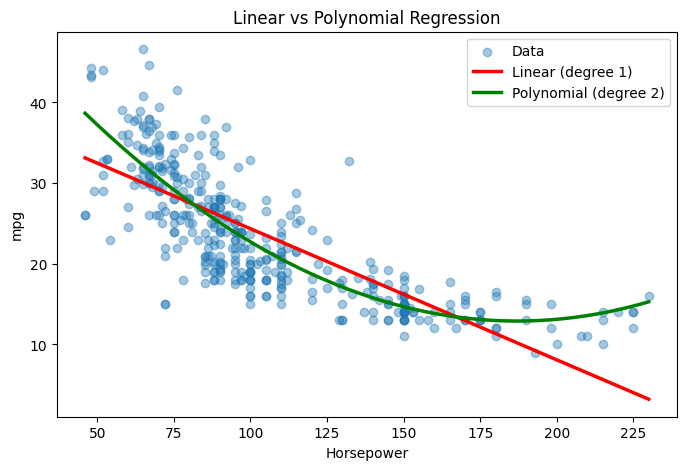

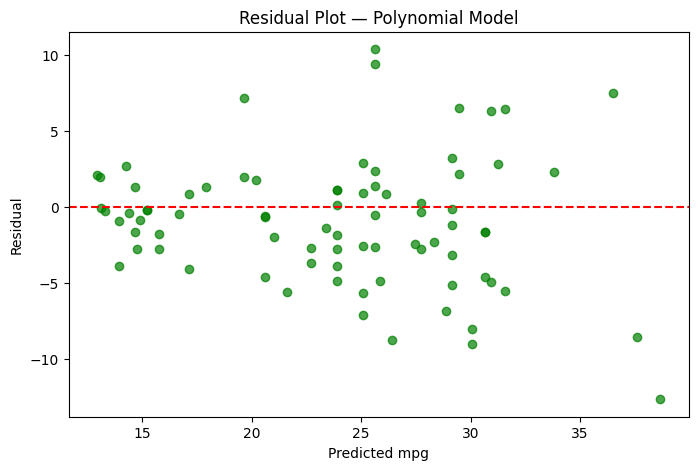

In [29]:
# ## Step 16: Predict and evaluate

# In[18]:


y_pred_poly = poly_model.predict(X_test_poly)

mae_poly  = mean_absolute_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
r2_poly   = r2_score(y_test, y_pred_poly)

print(f"MAE : {mae_poly:.2f} mpg")
print(f"RMSE: {rmse_poly:.2f} mpg")
print(f"R²  : {r2_poly:.3f}")


# ## Step 17: Compare both models visually

# In[19]:


plt.scatter(X, y, alpha=0.4, label="Data")
plt.plot(x_line, lin_model.predict(x_line), color="red", linewidth=2.5, label="Linear (degree 1)")
plt.plot(x_line, poly_model.predict(poly.transform(x_line)), color="green", linewidth=2.5, label="Polynomial (degree 2)")
plt.xlabel("Horsepower")
plt.ylabel("mpg")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()


# In[20]:


results = pd.DataFrame({
    "Model": ["Linear", "Polynomial (deg 2)"],
    "MAE":  [mae_lin, mae_poly],
    "RMSE": [rmse_lin, rmse_poly],
    "R²":   [r2_lin, r2_poly],
}).round(3)
results


# The curve fits better: **lower errors** and **higher R²**.

# ## Step 18: Residuals of the polynomial model

# In[21]:


plt.scatter(y_pred_poly, y_test - y_pred_poly, alpha=0.7, color="green")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted mpg")
plt.ylabel("Residual")
plt.title("Residual Plot — Polynomial Model")
plt.show()


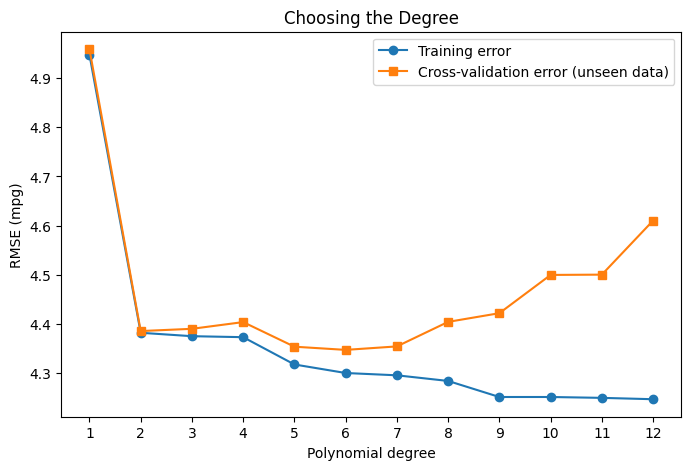

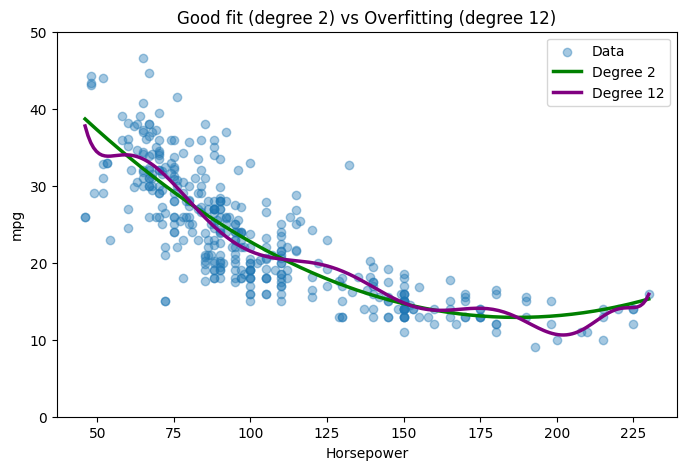

Linear model predicts    : 16.2 mpg
Polynomial model predicts: 14.7 mpg


In [30]:
# The U-shape is gone — the errors now look much more random. 👍

# ---
# # Part C: How high should the degree go? (Overfitting)
# 
# If degree 2 is better, is degree 10 even better? Let's test degrees 1 to 12.
# 
# Two new tools here:
# - **StandardScaler** — horsepower¹² is an enormous number, which confuses the computer. Scaling first keeps the numbers small.
# - **Pipeline** — chains the steps (scale → polynomial → regression) into one model.
# - **Cross-validation** — instead of judging on one split, split the training data into 10 parts, test on each part in turn, and average. Gives a much more reliable score.

# In[22]:


from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold

degrees = range(1, 13)
cv = KFold(n_splits=10, shuffle=True, random_state=42)
train_rmse, cv_rmse = [], []

for d in degrees:
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=d, include_bias=False),
        LinearRegression()
    )
    # error on the data the model trained on
    model.fit(X_train, y_train)
    train_rmse.append(np.sqrt(mean_squared_error(y_train, model.predict(X_train))))

    # average error on unseen folds (cross-validation)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    cv_rmse.append(-scores.mean())

pd.DataFrame({"Degree": degrees, "Train RMSE": train_rmse, "CV RMSE (unseen)": cv_rmse}).round(3)


# In[23]:


plt.plot(degrees, train_rmse, "o-", label="Training error")
plt.plot(degrees, cv_rmse, "s-", label="Cross-validation error (unseen data)")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (mpg)")
plt.title("Choosing the Degree")
plt.xticks(degrees)
plt.legend()
plt.show()


# **What to teach here**
# - Going from degree **1 → 2** gives a **big** drop in error.
# - After degree 2 the improvement is **tiny** — extra complexity buys almost nothing.
# - At high degrees the unseen-data error **rises** while training error stays low — that is **overfitting**: the model memorizes noise instead of learning the pattern.
# - Rule of thumb: pick the **simplest model** that performs well → **degree 2**.

# In[24]:


# See overfitting with your own eyes: degree 2 vs degree 12
plt.scatter(X, y, alpha=0.4, label="Data")
for d, color in [(2, "green"), (12, "purple")]:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(degree=d, include_bias=False), LinearRegression())
    m.fit(X_train, y_train)
    plt.plot(x_line, m.predict(x_line), color=color, linewidth=2.5, label=f"Degree {d}")
plt.ylim(0, 50)
plt.xlabel("Horsepower")
plt.ylabel("mpg")
plt.title("Good fit (degree 2) vs Overfitting (degree 12)")
plt.legend()
plt.show()


# The degree-12 curve wiggles to chase individual points, especially at the edges — it won't generalize well to new cars.

# ---
# ## Step 19: Use the models to make predictions
# A new car has **150 horsepower**. What mpg should we expect?

# In[25]:


new_car = pd.DataFrame({"horsepower": [150]})

pred_lin  = lin_model.predict(new_car)[0]
pred_poly = poly_model.predict(poly.transform(new_car))[0]

print(f"Linear model predicts    : {pred_lin:.1f} mpg")
print(f"Polynomial model predicts: {pred_poly:.1f} mpg")


# ---
# ## Summary
# 
# | Concept | Key point |
# |---|---|
# | Linear Regression | Fits a straight line: $y = b_0 + b_1x$ |
# | Polynomial Regression | Adds $x^2, x^3, …$ so the line can curve — still solved with linear regression |
# | Train/Test split | Judge models on data they have never seen |
# | Residual plot | A pattern in residuals = model is missing something |
# | Cross-validation | Average score over many splits — more reliable than one test set |
# | Overfitting | Too complex a model memorizes noise; error on new data goes up |
# 
# ## Practice exercises for students
# 1. Replace `horsepower` with `weight`. Is the relationship curved too?
# 2. Try `degree=3`. Does test R² improve over degree 2?
# 3. Change `random_state` to 0 and rerun. Do the results change much? Why?
# 4. **Multiple regression:** use `X = df[["horsepower", "weight"]]`. Does R² go up?
# 5. Predict the mpg of a car with 60 horsepower and with 230 horsepower using both models. Which predictions seem more reali